In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Search for the CSV inside the current project folder and subfolders
project_folder = Path.cwd()

csv_files = [
    file for file in project_folder.rglob("*.csv")
    if "turkish" in file.name.lower()
]

if not csv_files:
    raise FileNotFoundError(
        "CSV not found. Make sure turkishCF.csv is inside the project folder."
    )

file_path = csv_files[0]
print("Dataset file:", file_path)

# Load the semicolon-separated dataset
df = pd.read_csv(file_path, sep=";", encoding="utf-8-sig")

print("\nDataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset file: C:\Users\kavya\Turkish Crowdfunding Startups\dataset\turkish+crowdfunding+startups\turkishCF.csv

Dataset loaded successfully!
Dataset shape: (1628, 38)


,id,platform_adi,kitle_fonlamasi_turu,kategori,fon_sekli,proje_adi,proje_sahibi,proje_sahibi_cinsiyet,kac_proje_destekledi,kac_projeye_abone,...,sosyal_medya,sm_sayisi,sm_takipci,etiket_sayisi,icerik_kelime_sayisi,proje_aciklamasi,hedef_miktari,toplanan_tutar,destek_orani,basari_durumu
0,1,fongogo,ödül,diğer,ya hep ya hiç,Gerçek Gizlidir Filmleri,Lob Ekibi,belirsiz,1,0,...,var,3,274,0,301,Türkiye’de ilk kez her aşaması ‘online’ olarak...,40000,54410,136%,başarılı
1,2,fongogo,ödül,diğer,ya hep ya hiç,Fongogo - Hayat Bulsun!,Fongogo Team,belirsiz,3,0,...,var,3,5634,0,167,"Fongogo ekibi olarak büyümek, daha geniş kitle...",50000,50110,100%,başarılı
2,3,fongogo,ödül,diğer,ya hep ya hiç,"PAYLAŞIMIN, SEVGİNİN VE ÇOCUKLARIN İYİLİK EVİ ...",SİNEM CAN,kadın,0,0,...,var,2,510,4,413,Çocuklara her şeyin ücretsiz olduğu iyilik evi...,47000,47850,101%,başarılı
3,4,fongogo,ödül,diğer,ya hep ya hiç,Türk Kadının 100.yıl Seyri,Deniz Tutkusu Seyirde,kadın,0,0,...,var,2,3338,5,287,‘Sözde değil Özde İzindeyiz ‘ sloganıyla Atatü...,35000,35450,101%,başarılı
4,5,fongogo,ödül,diğer,ya hep ya hiç,Doğadaki Çocuk,Seren Kutadgu,kadın,2,0,...,var,1,144,3,571,İstanbul'daki çocuk yuvalarında yaşayan dezava...,30000,31250,104%,başarılı


In [3]:
# Dataset dimensions
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

# Column names and data types
print("\nDataset Information:")
df.info()

# Statistical summary
print("\nStatistical Summary:")
display(df.describe(include="all").T)

Number of rows: 1628
Number of columns: 38

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1628 entries, 0 to 1627
Data columns (total 38 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   id                     1628 non-null   int64 
 1   platform_adi           1628 non-null   object
 2   kitle_fonlamasi_turu   1628 non-null   object
 3   kategori               1628 non-null   object
 4   fon_sekli              1628 non-null   object
 5   proje_adi              1628 non-null   object
 6   proje_sahibi           1628 non-null   object
 7   proje_sahibi_cinsiyet  1628 non-null   object
 8   kac_proje_destekledi   1628 non-null   int64 
 9   kac_projeye_abone      1628 non-null   int64 
 10  kac_projenin_sahibi    1628 non-null   int64 
 11  kac_proje_takiminda    1628 non-null   int64 
 12  konum                  1628 non-null   object
 13  bolge                  1627 non-null   object
 14  yil    

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,1628.0,NaN,NaN,NaN,814.5,470.107435,1.0,407.75,814.5,1221.25,1628.0
platform_adi,1628,6,fongogo,1075,NaN,NaN,NaN,NaN,NaN,NaN,NaN
kitle_fonlamasi_turu,1628,2,ödül,1618,NaN,NaN,NaN,NaN,NaN,NaN,NaN
kategori,1628,17,film-video-fotoğraf,389,NaN,NaN,NaN,NaN,NaN,NaN,NaN
fon_sekli,1628,2,ya hep ya hiç,1509,NaN,NaN,NaN,NaN,NaN,NaN,NaN
proje_adi,1628,1607,QUBİT'E HAYAL ORTAĞI OLUN,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
proje_sahibi,1628,1513,Percin Imrek,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
proje_sahibi_cinsiyet,1628,3,erkek,1148,NaN,NaN,NaN,NaN,NaN,NaN,NaN
kac_proje_destekledi,1628.0,NaN,NaN,NaN,0.429361,2.225029,0.0,0.0,0.0,0.0,31.0
kac_projeye_abone,1628.0,NaN,NaN,NaN,0.000614,0.024784,0.0,0.0,0.0,0.0,1.0


In [4]:
# Check missing values
missing_values = df.isnull().sum()

print("Missing values in each column:")
display(missing_values[missing_values > 0])

if missing_values.sum() == 0:
    print("No missing values found.")

# Check duplicate rows
duplicate_count = df.duplicated().sum()
print("\nNumber of duplicate rows:", duplicate_count)

Missing values in each column:


bolge                     1
proje_baslama_tarihi    611
proje_bitis_tarihi      553
dtype: int64


Number of duplicate rows: 0


In [5]:
# Identify numerical and categorical columns
numerical_columns = df.select_dtypes(include=["number"]).columns.tolist()
categorical_columns = df.select_dtypes(include=["object", "category", "bool"]).columns.tolist()

print("Numerical features:", len(numerical_columns))
print(numerical_columns)

print("\nCategorical features:", len(categorical_columns))
print(categorical_columns)

Numerical features: 21
['id', 'kac_proje_destekledi', 'kac_projeye_abone', 'kac_projenin_sahibi', 'kac_proje_takiminda', 'yil', 'gun_sayisi', 'video_uzunlugu', 'gorsel_sayisi', 'sss', 'guncellemeler', 'yorumlar', 'destekci_sayisi', 'odul_sayisi', 'ekip_kisi_sayisi', 'sm_sayisi', 'sm_takipci', 'etiket_sayisi', 'icerik_kelime_sayisi', 'hedef_miktari', 'toplanan_tutar']

Categorical features: 17
['platform_adi', 'kitle_fonlamasi_turu', 'kategori', 'fon_sekli', 'proje_adi', 'proje_sahibi', 'proje_sahibi_cinsiyet', 'konum', 'bolge', 'proje_baslama_tarihi', 'proje_bitis_tarihi', 'tanitim_videosu', 'web_sitesi', 'sosyal_medya', 'proje_aciklamasi', 'destek_orani', 'basari_durumu']


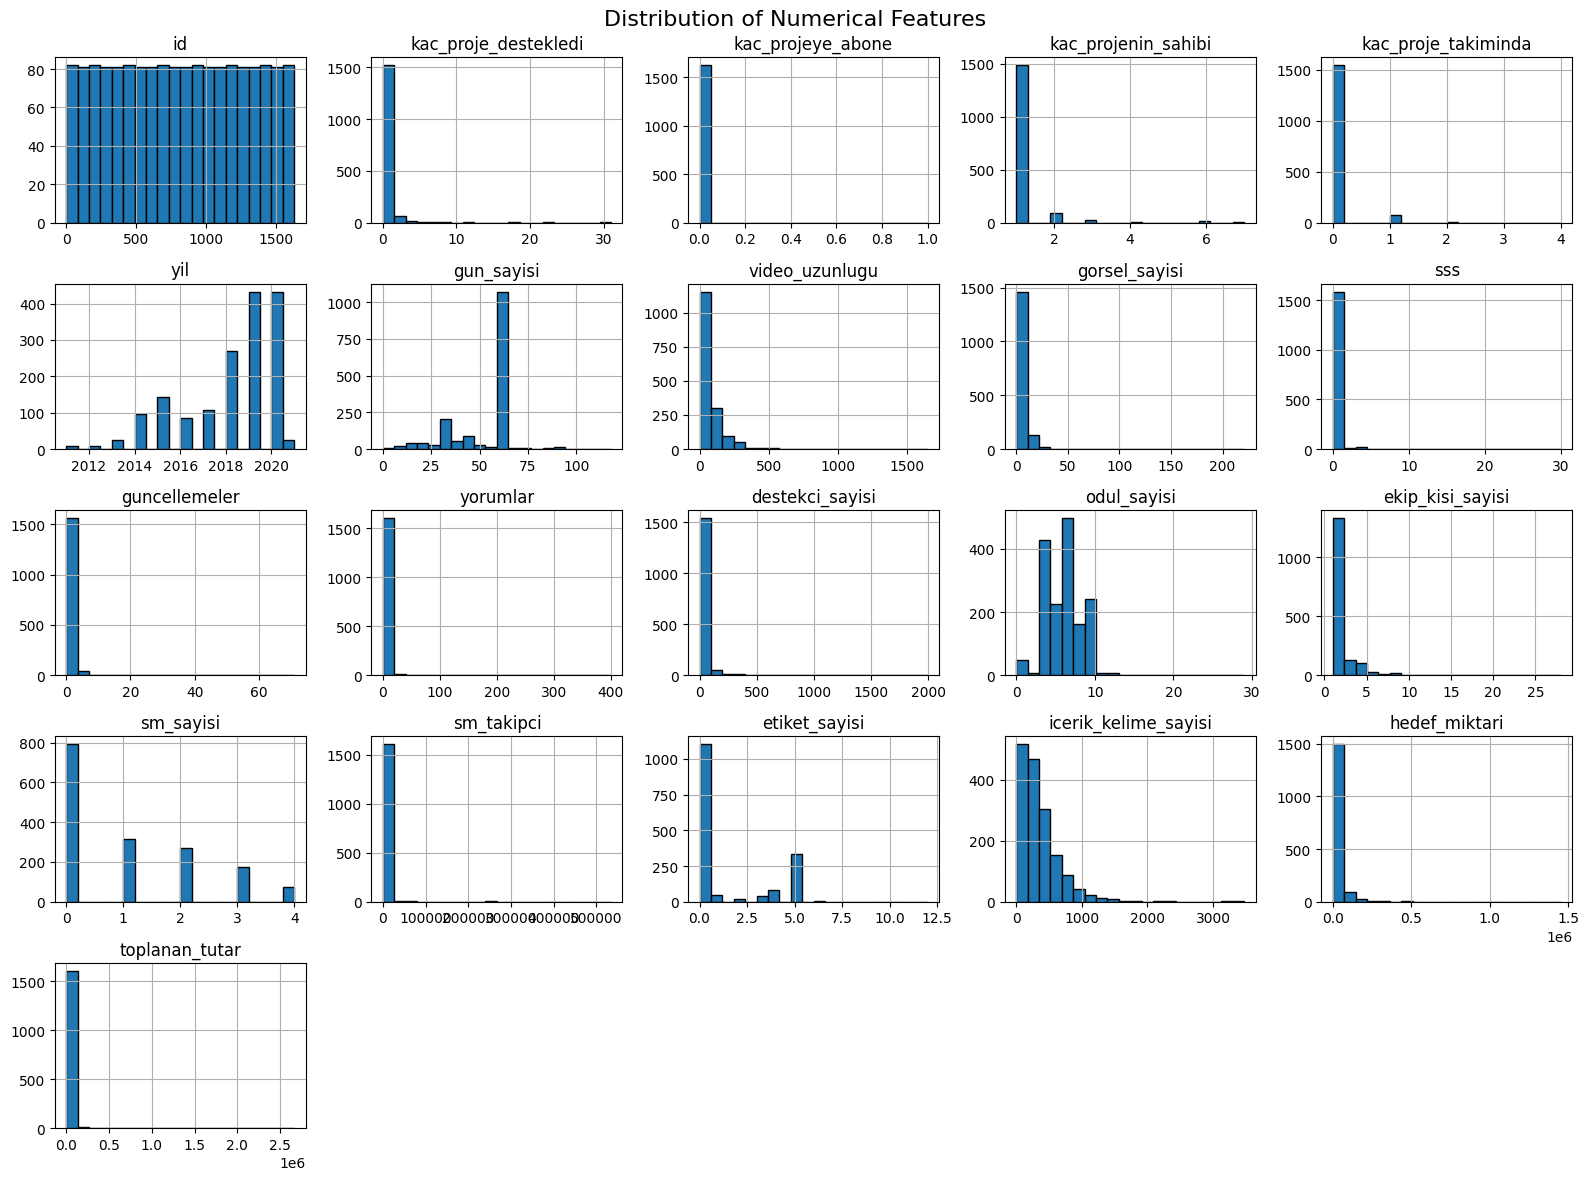

In [7]:
if numerical_columns:
    df[numerical_columns].hist(
        figsize=(16, 12),
        bins=20,
        edgecolor="black"
    )

    plt.suptitle("Distribution of Numerical Features", fontsize=16)
    plt.tight_layout()
    plt.show()
else:
    print("No numerical columns detected.")

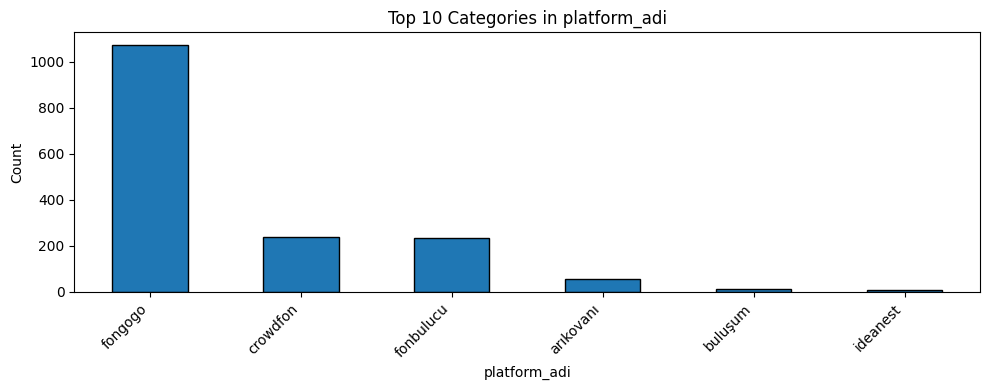

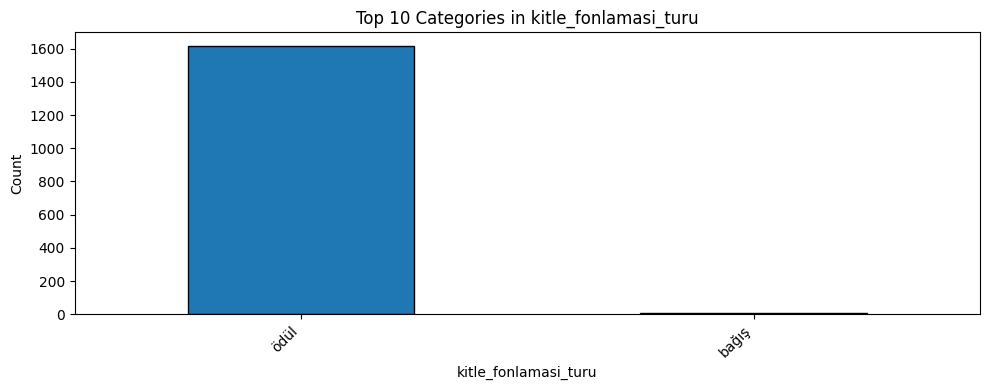

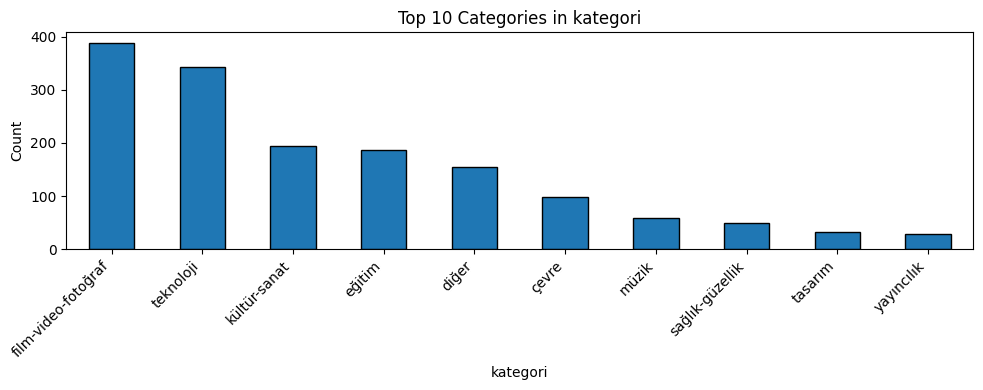

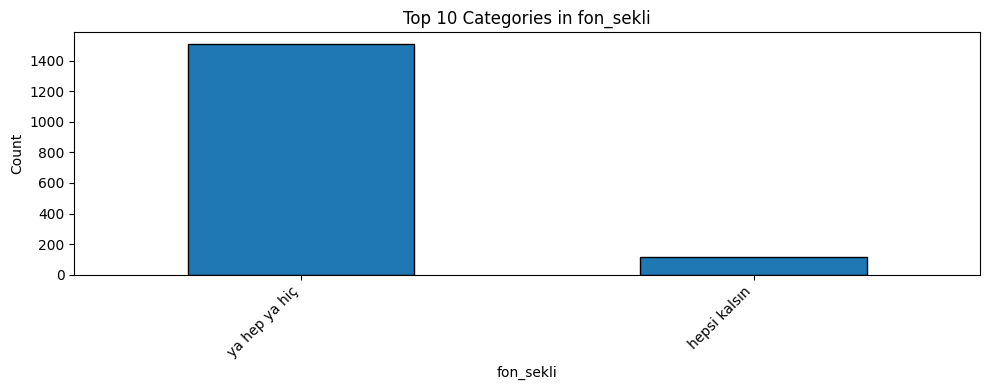

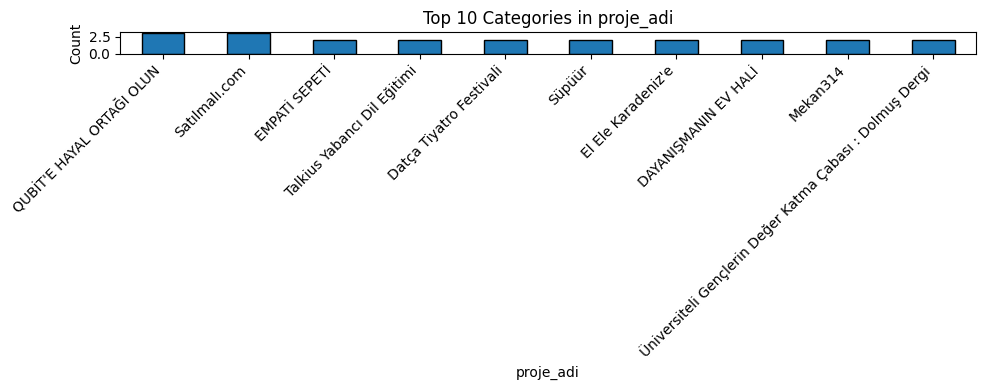

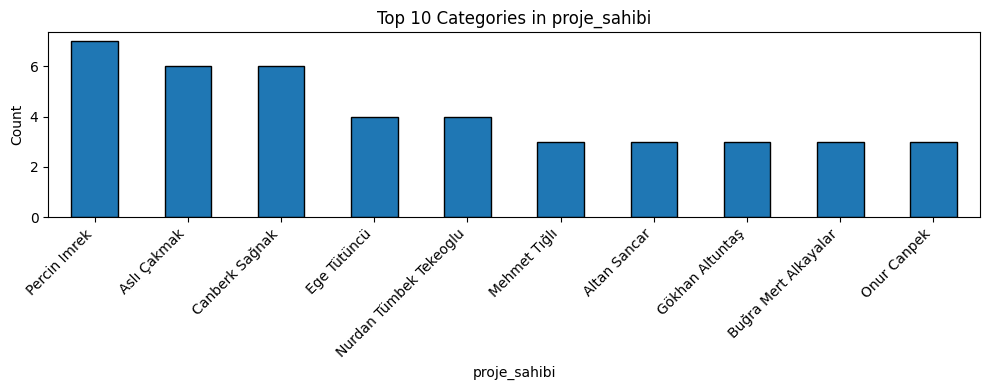

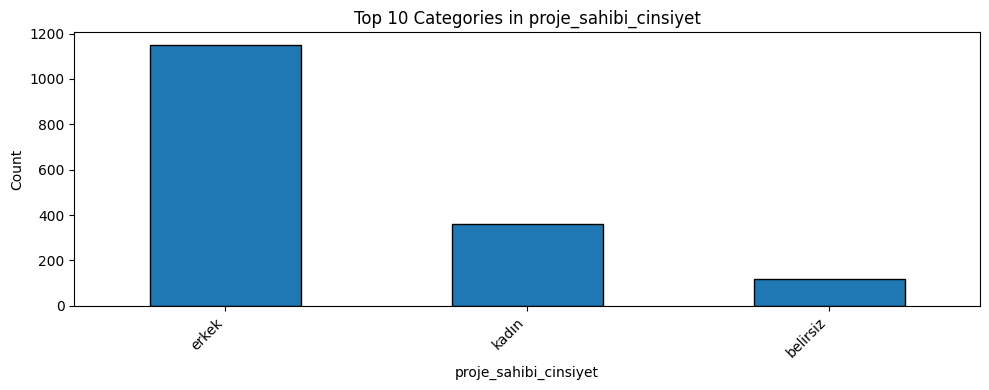

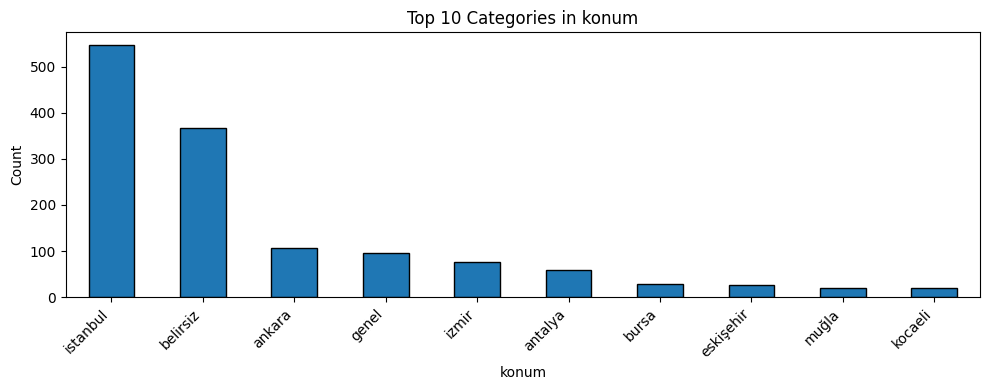

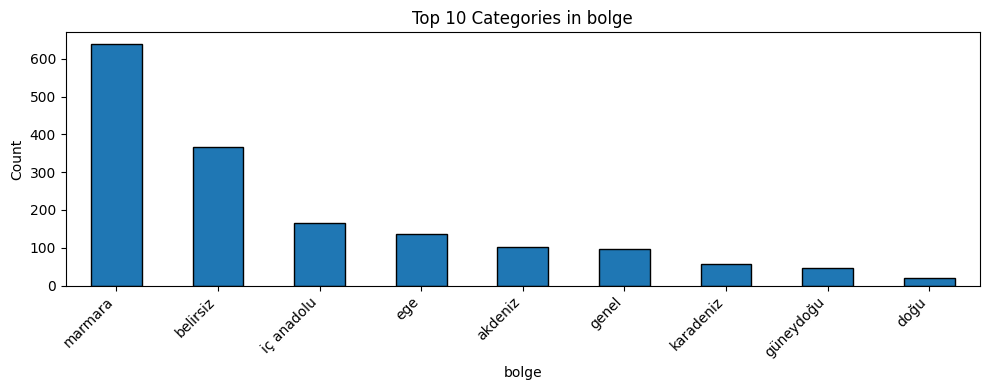

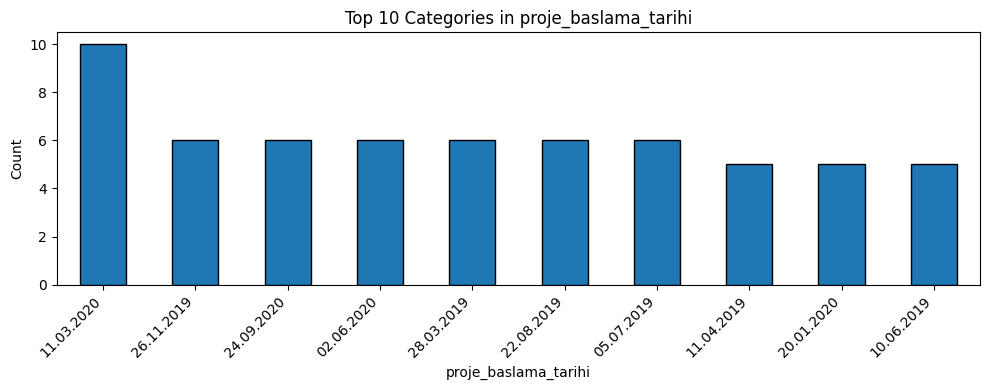

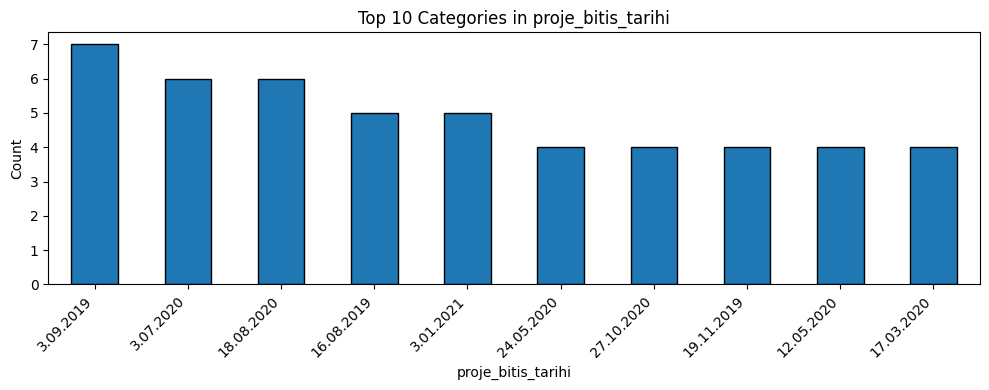

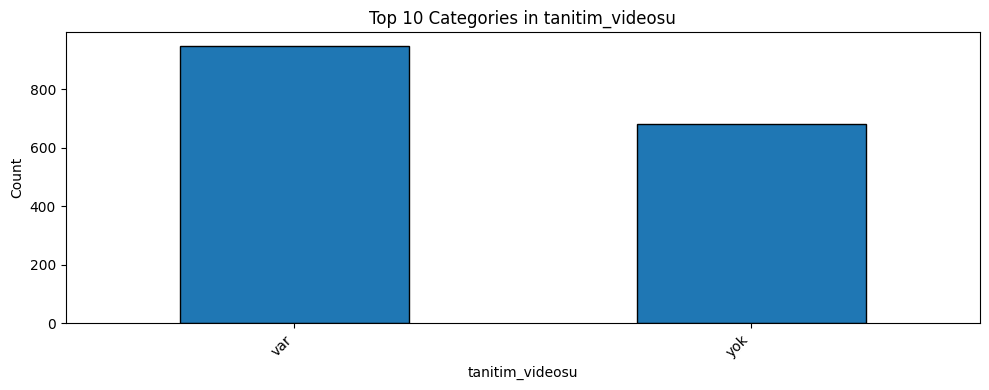

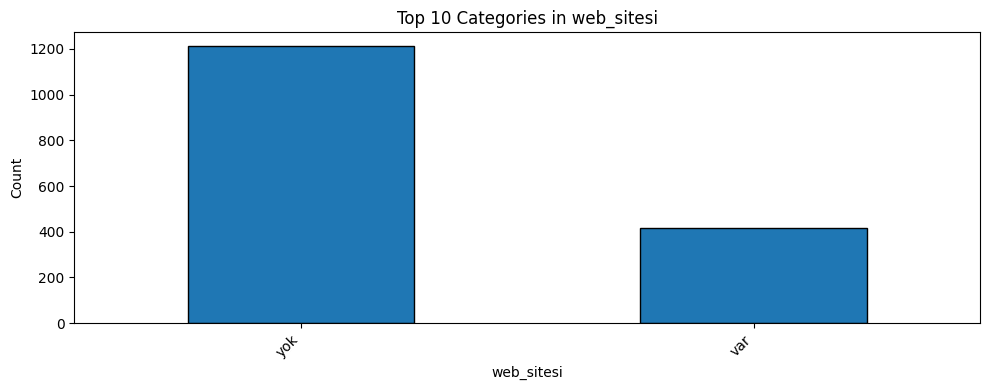

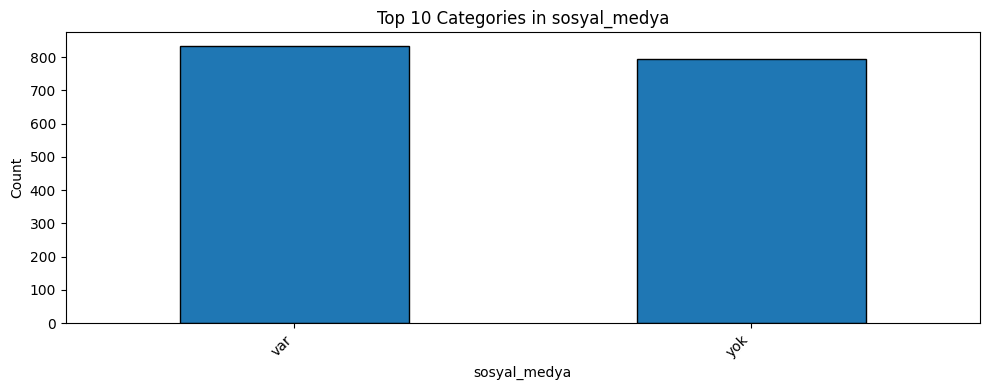

C:\Users\kavya\AppData\Local\Temp\ipykernel_6872\1972716692.py:11: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


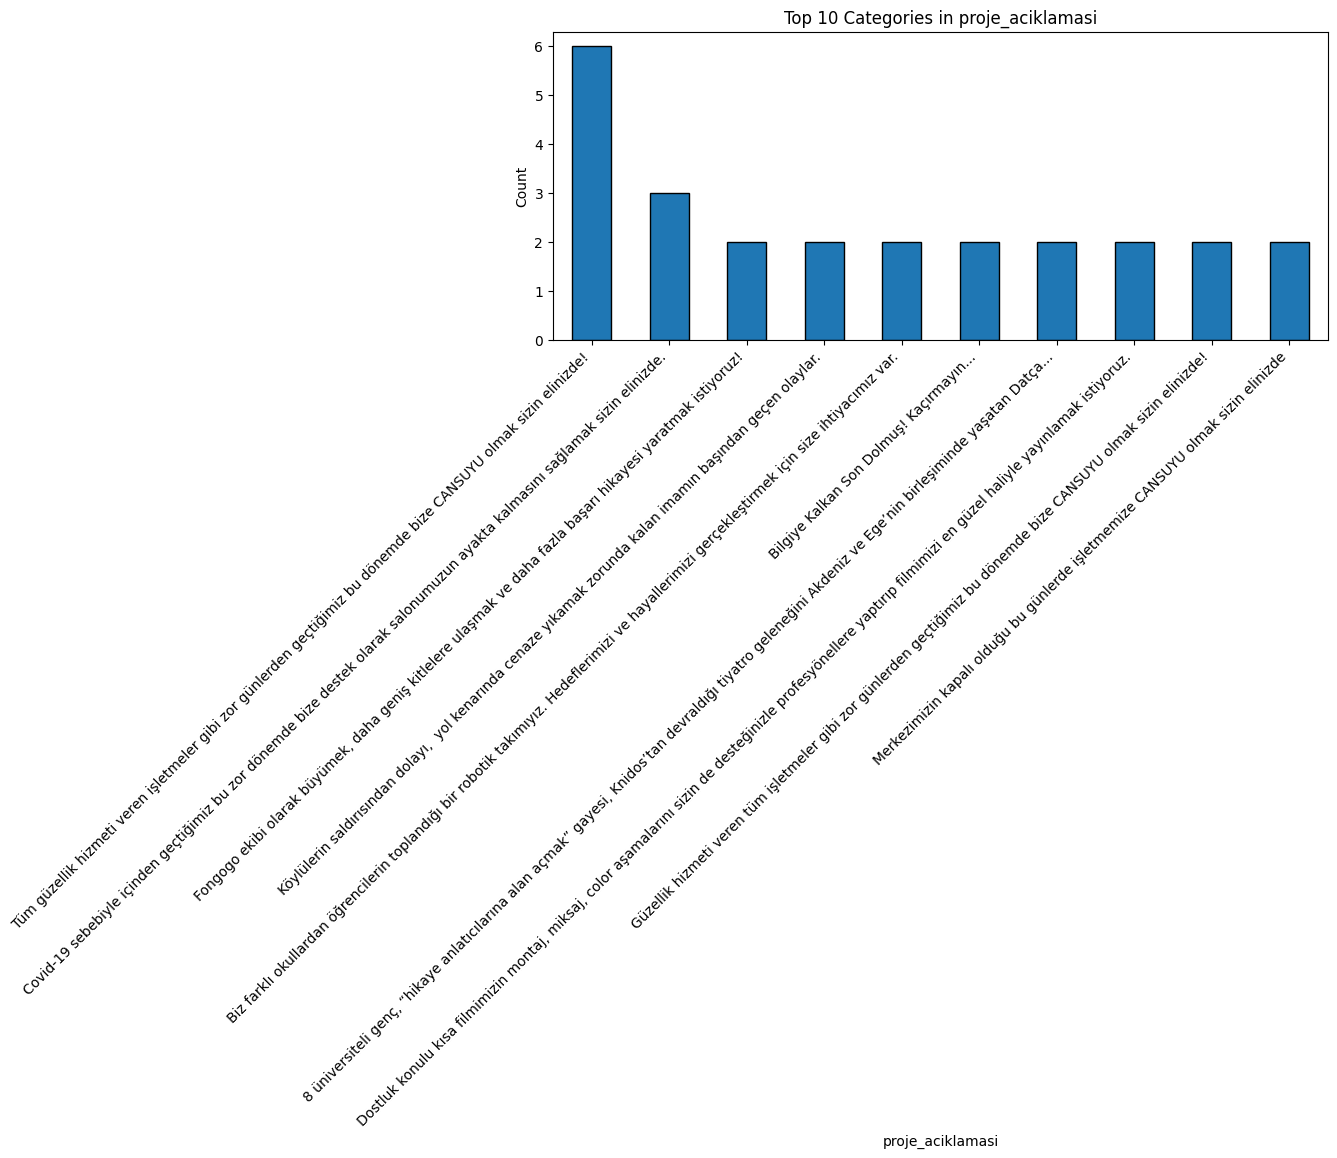

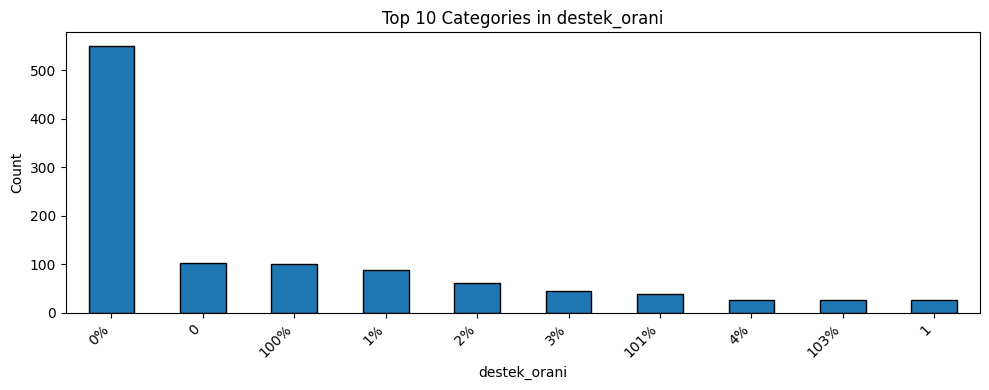

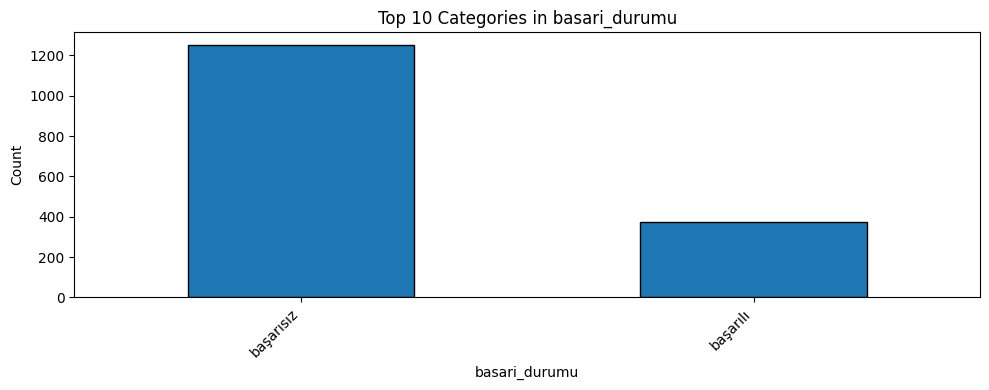

In [8]:
for column in categorical_columns:
    if df[column].nunique() > 1:
        top_categories = df[column].value_counts().head(10)

        plt.figure(figsize=(10, 4))
        top_categories.plot(kind="bar", edgecolor="black")
        plt.title(f"Top 10 Categories in {column}")
        plt.xlabel(column)
        plt.ylabel("Count")
        plt.xticks(rotation=45, ha="right")
        plt.tight_layout()
        plt.show()

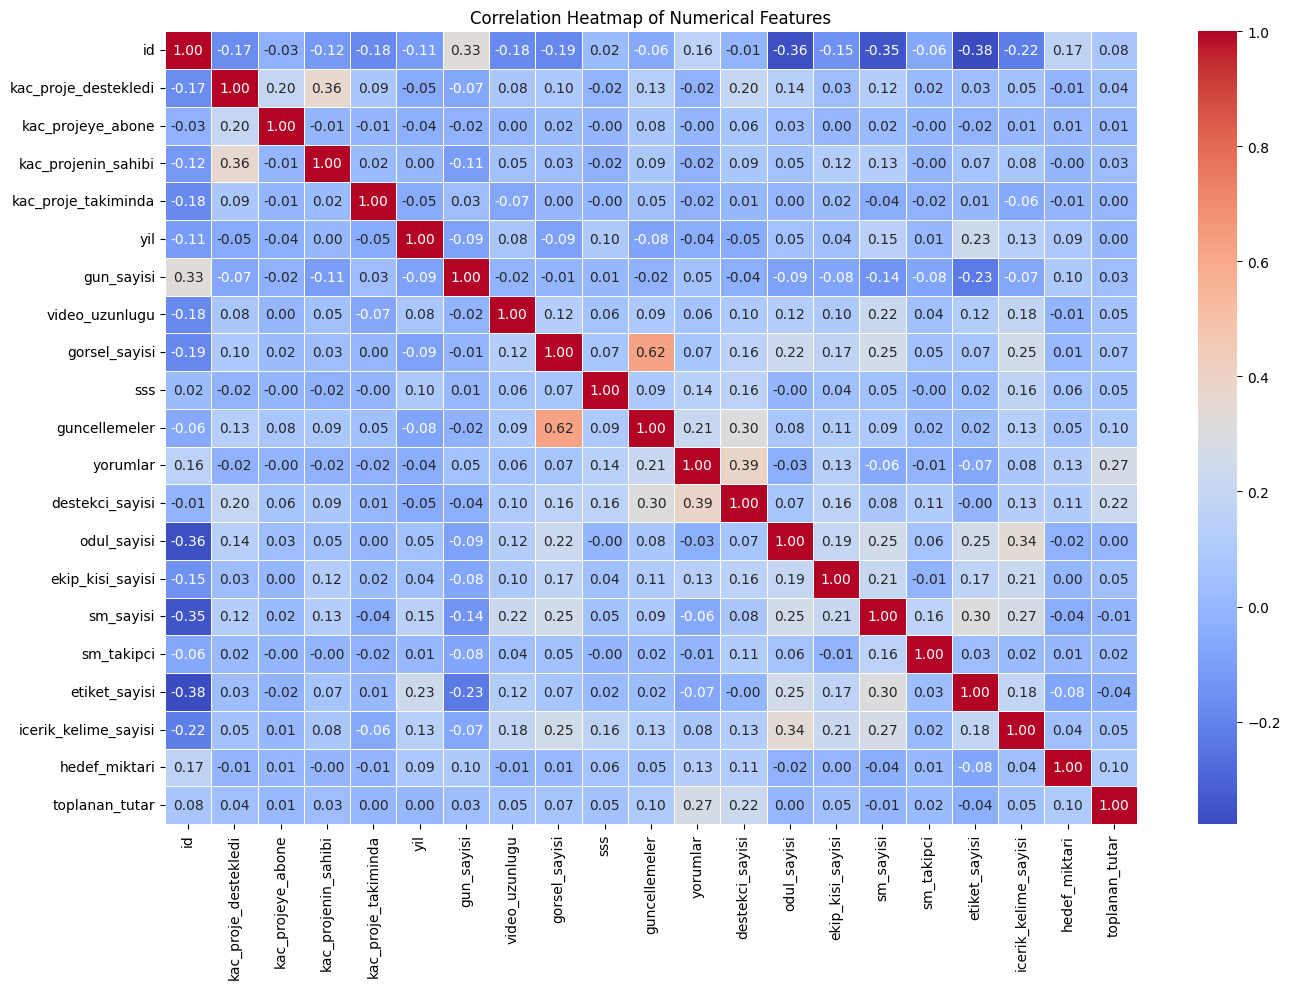

In [9]:
if len(numerical_columns) >= 2:
    correlation_matrix = df[numerical_columns].corr()

    plt.figure(figsize=(14, 10))
    sns.heatmap(
        correlation_matrix,
        annot=True,
        cmap="coolwarm",
        fmt=".2f",
        linewidths=0.5
    )

    plt.title("Correlation Heatmap of Numerical Features")
    plt.tight_layout()
    plt.show()
else:
    print("Not enough numerical columns for correlation analysis.")

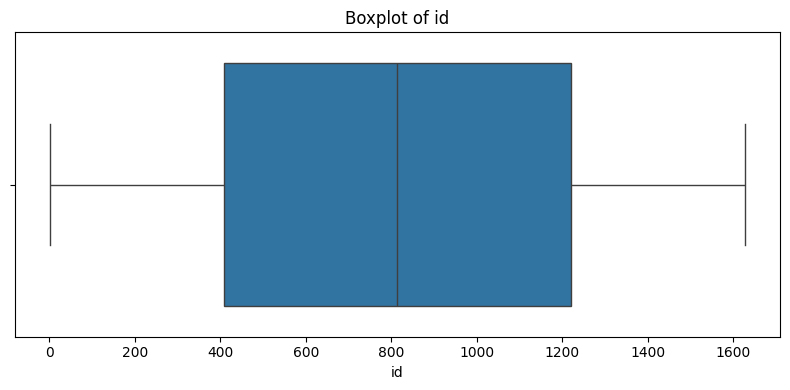

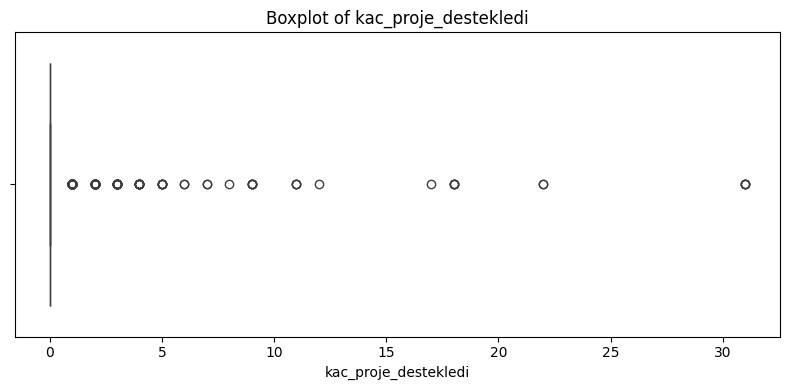

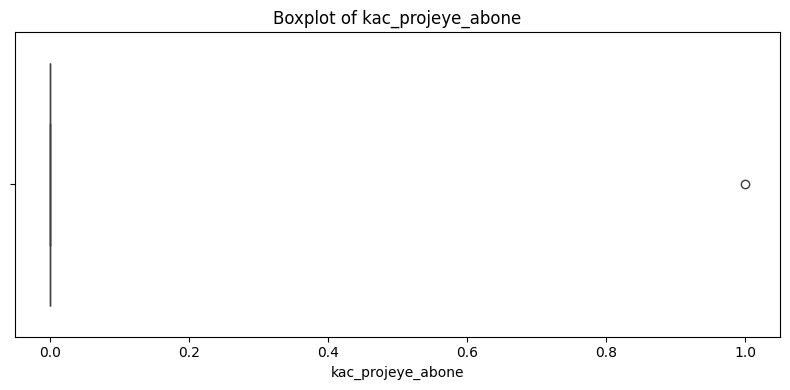

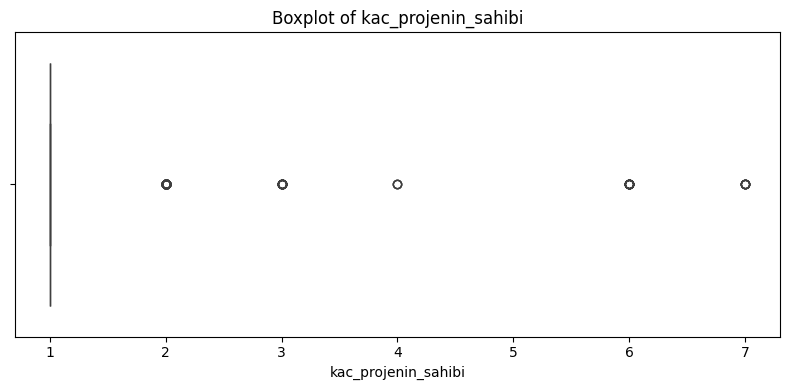

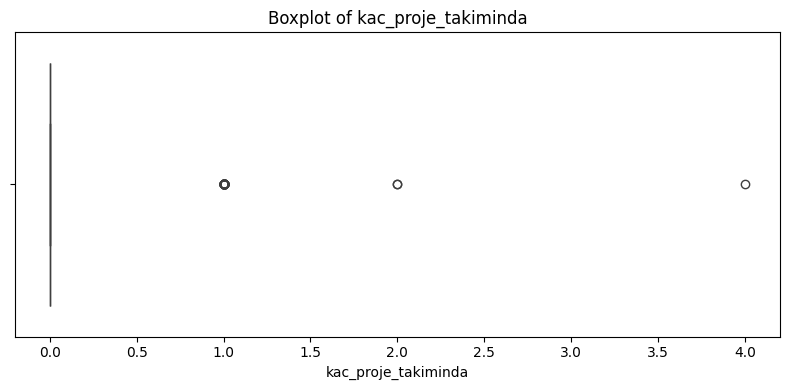

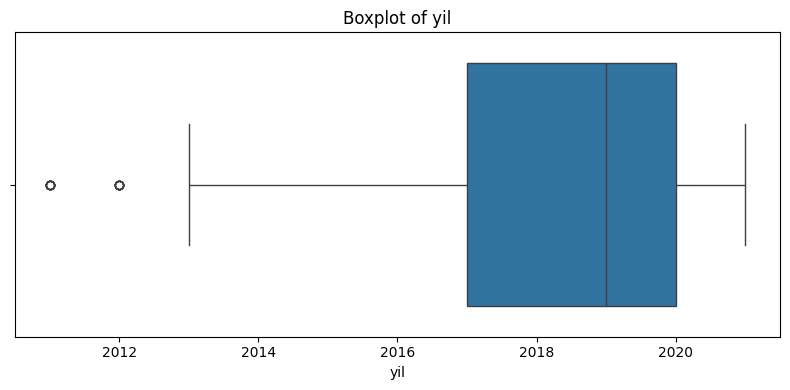

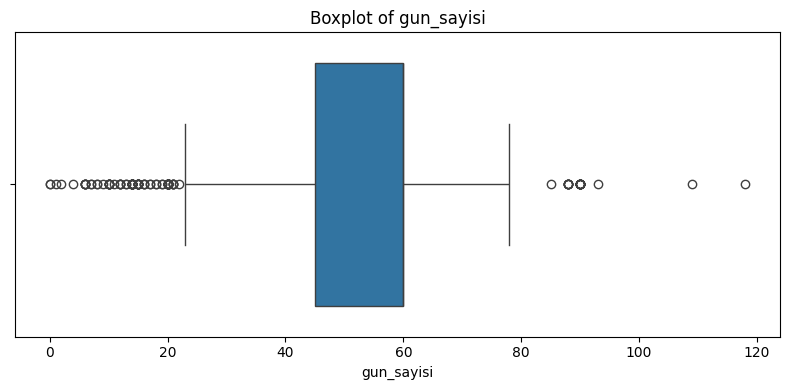

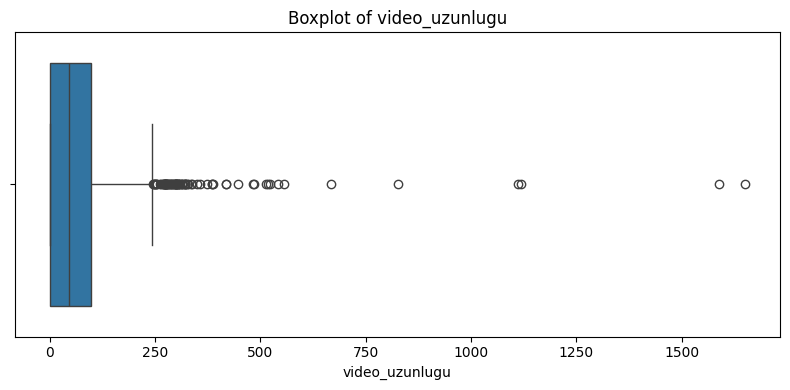

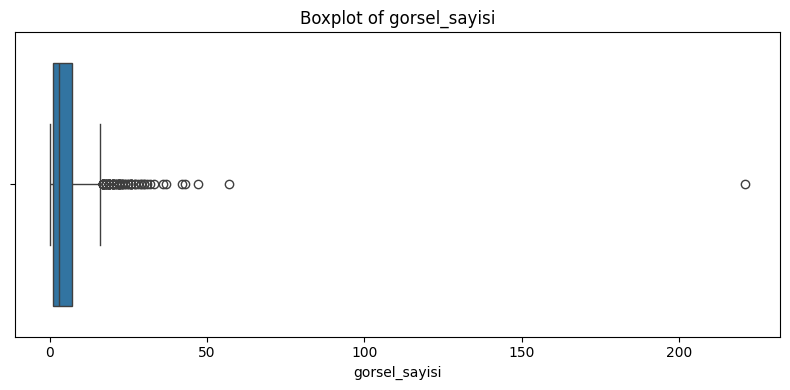

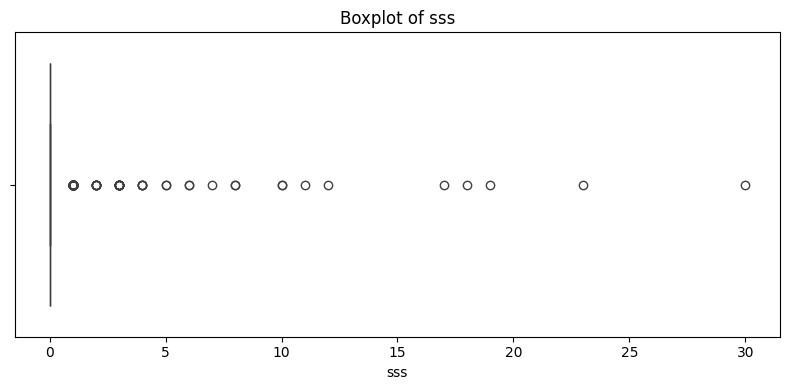

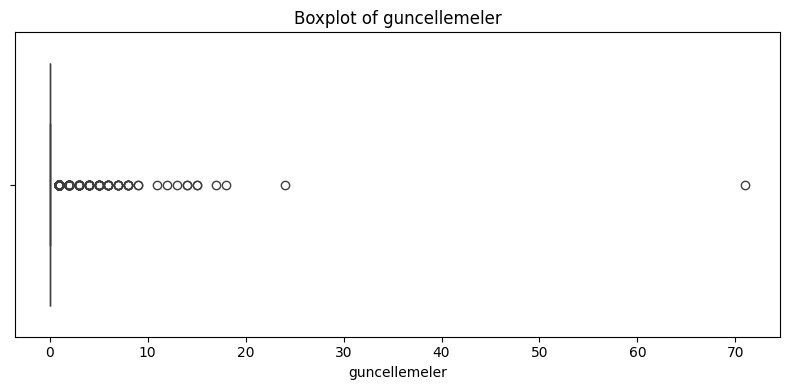

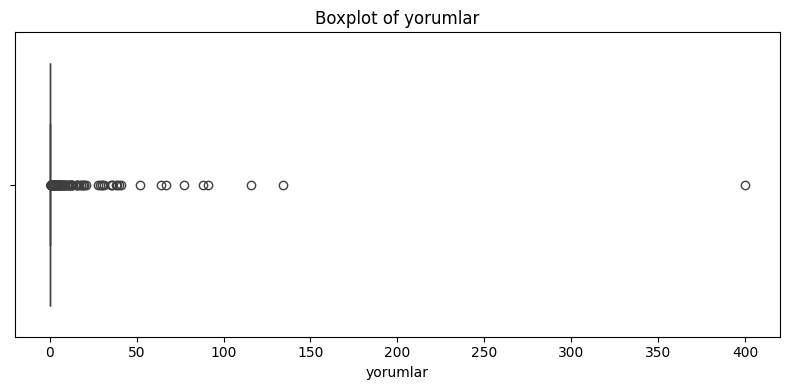

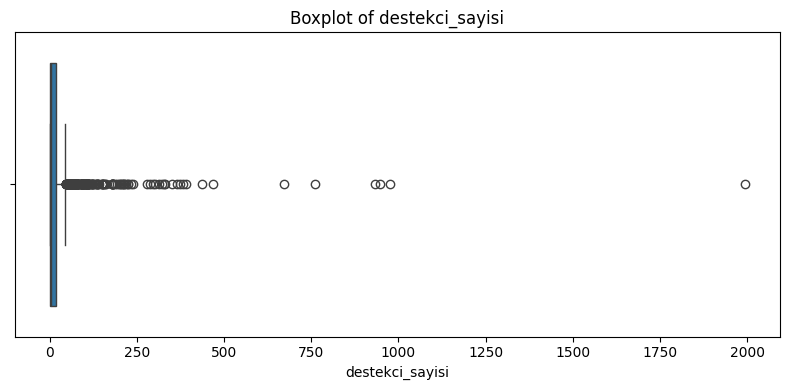

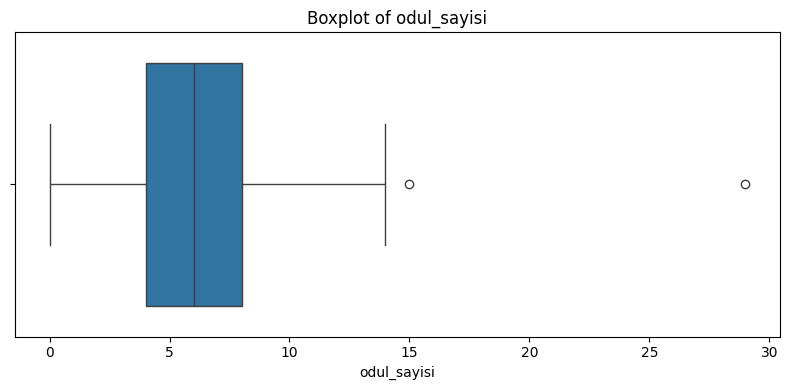

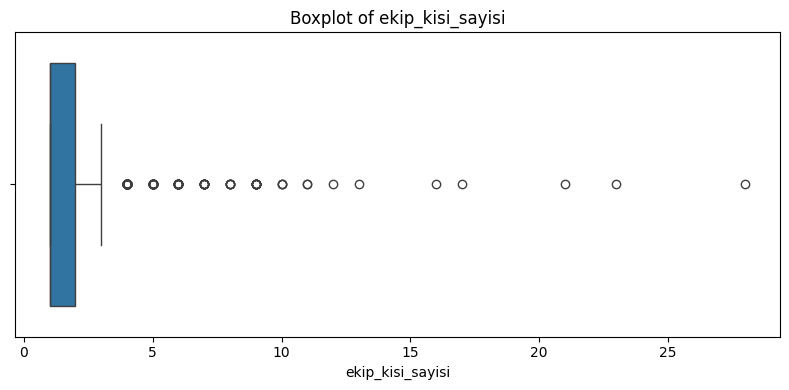

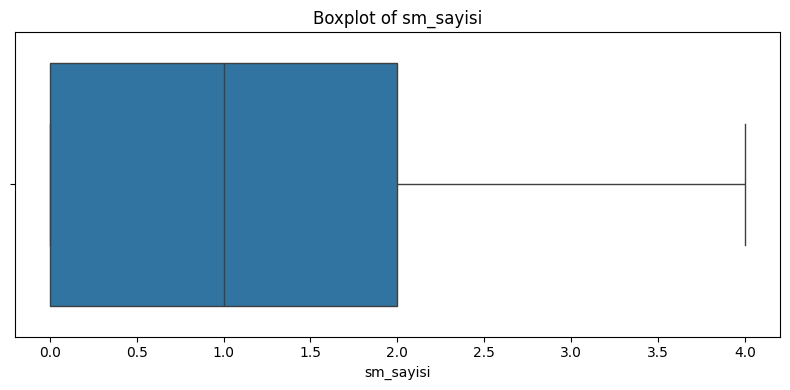

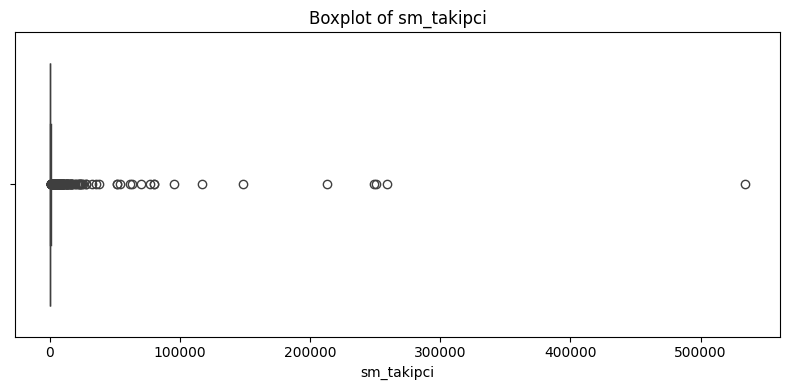

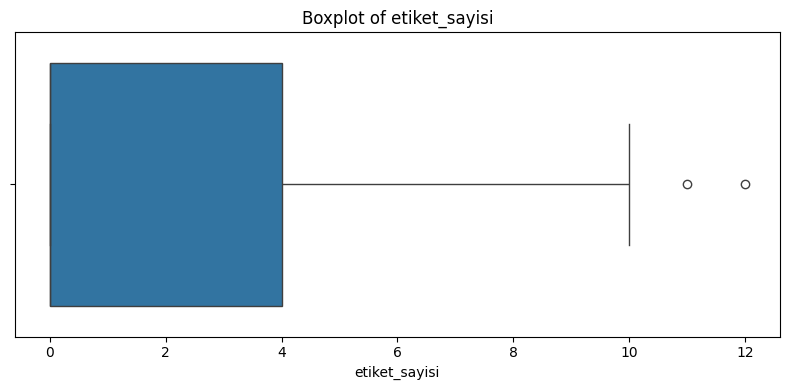

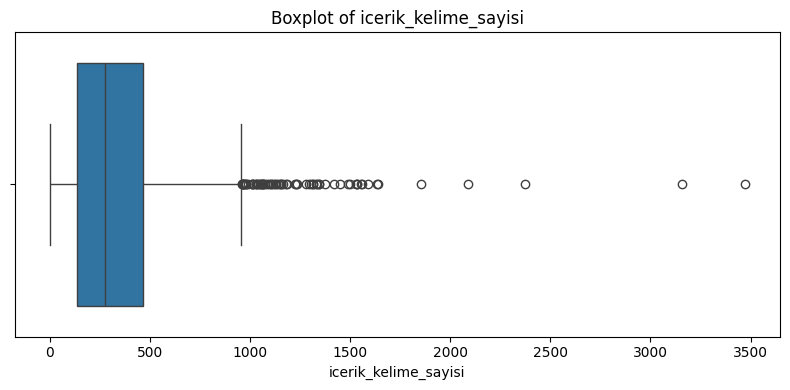

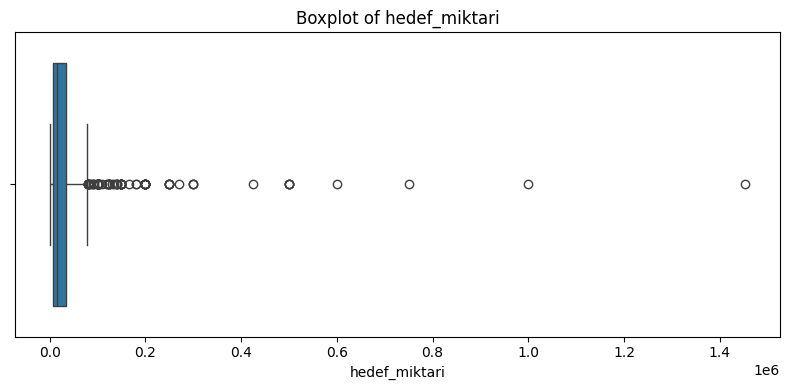

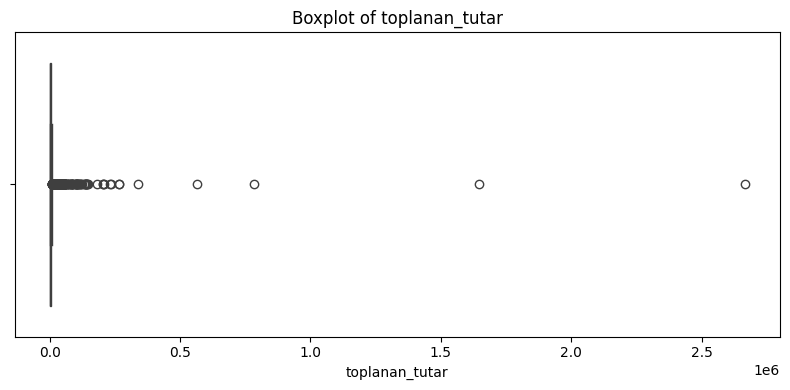

In [10]:
if numerical_columns:
    for column in numerical_columns:
        plt.figure(figsize=(8, 4))
        sns.boxplot(x=df[column])
        plt.title(f"Boxplot of {column}")
        plt.xlabel(column)
        plt.tight_layout()
        plt.show()
else:
    print("No numerical columns available for boxplots.")

## Result

Exploratory Data Analysis (EDA) was performed on the Turkish Crowdfunding Startups dataset. The dataset was examined to understand its structure, feature types, missing values, duplicate records, and distributions of numerical and categorical features. Visualizations such as histograms, bar charts, correlation heatmaps, and boxplots were used where applicable.

## Conclusion

The Turkish Crowdfunding Startups dataset was successfully explored. The analysis provided an understanding of the dataset's characteristics and feature distributions. Since the project focuses on clustering, the dataset will be further preprocessed and prepared for unsupervised machine learning.